(10000, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  10000 non-null  object 
 1   age                     10000 non-null  int64  
 2   country                 10000 non-null  object 
 3   city                    10000 non-null  object 
 4   customer_segment        10000 non-null  object 
 5   tenure_months           10000 non-null  int64  
 6   signup_channel          10000 non-null  object 
 7   contract_type           10000 non-null  object 
 8   monthly_logins          10000 non-null  int64  
 9   weekly_active_days      10000 non-null  int64  
 10  avg_session_time        10000 non-null  float64
 11  features_used           10000 non-null  int64  
 12  usage_growth_rate       10000 non-null  float64
 13  last_login_days_ago     10000 non-null  int64  
 14  monthly_fee             100

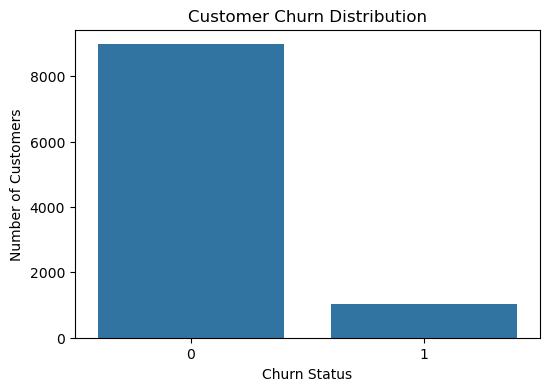

Churn Distribution
churn
0    8979
1    1021
Name: count, dtype: int64

churn
0    89.79
1    10.21
Name: proportion, dtype: float64


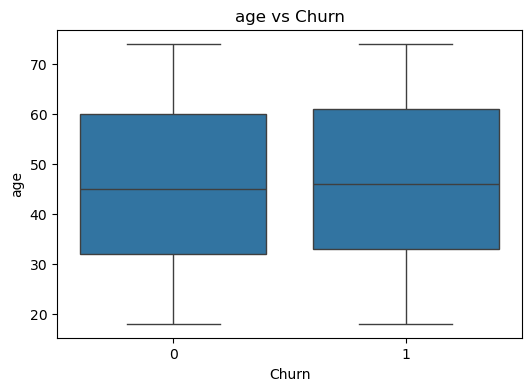

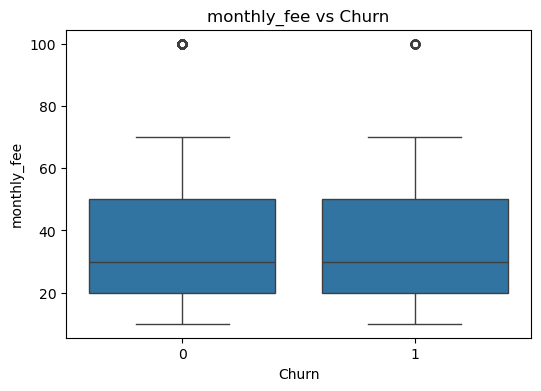

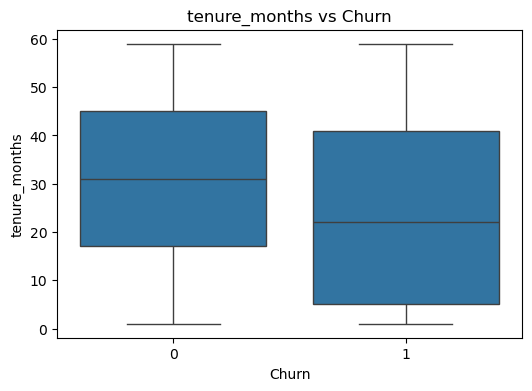

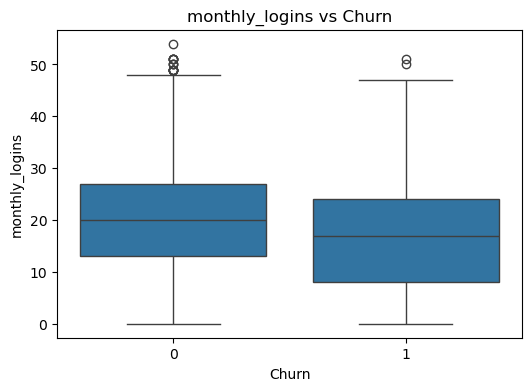

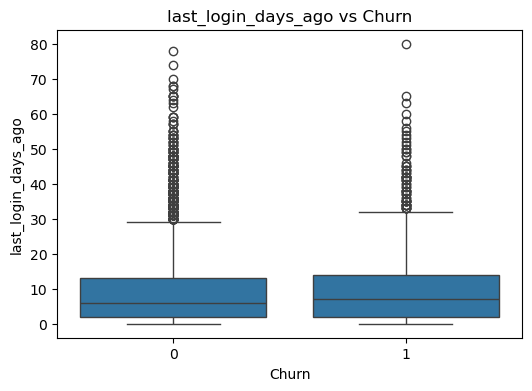

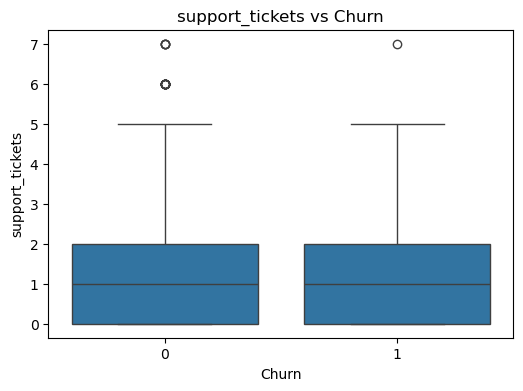

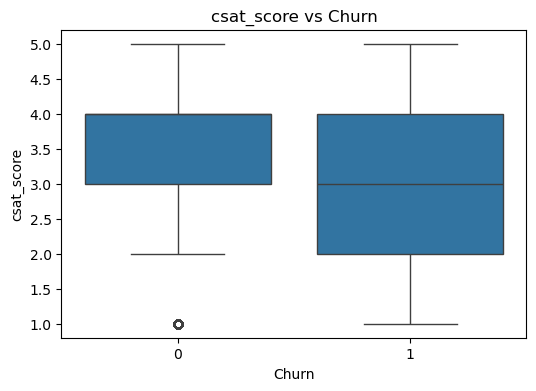

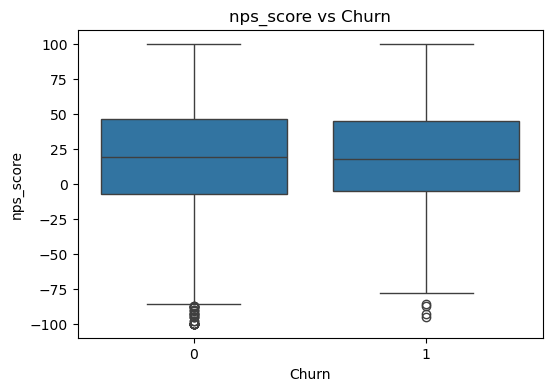

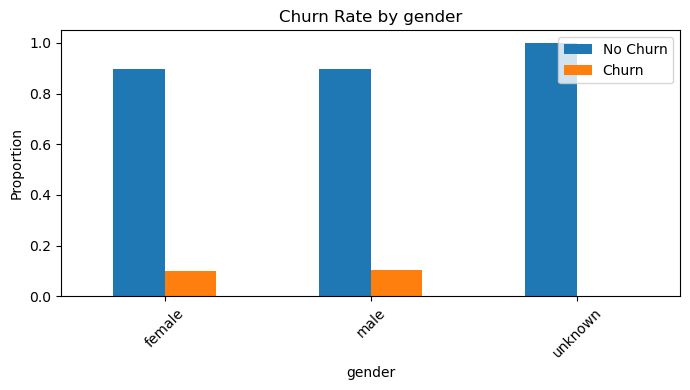

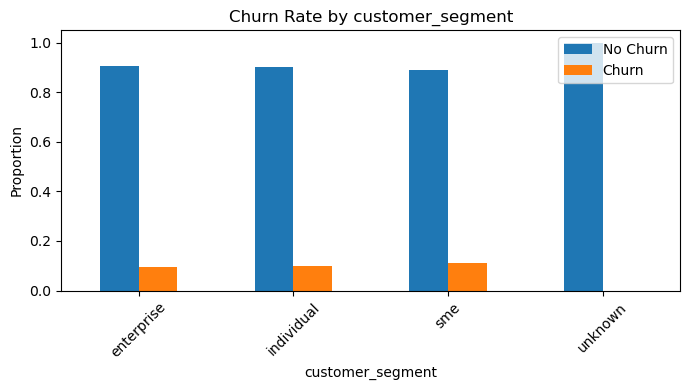

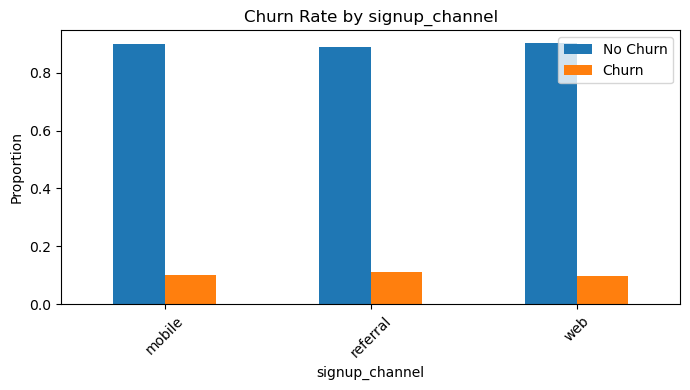

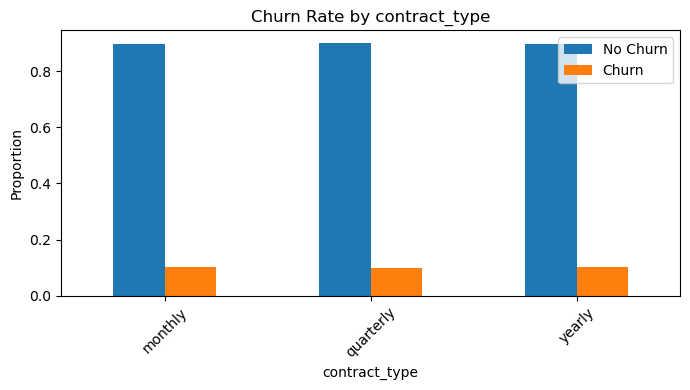

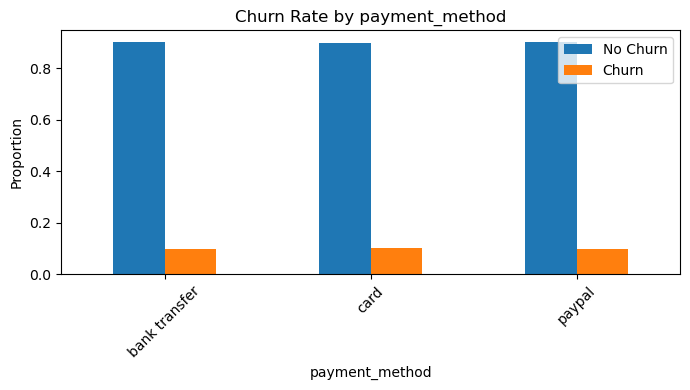

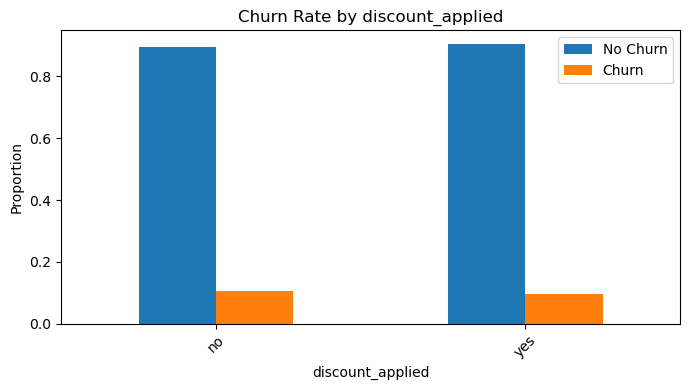

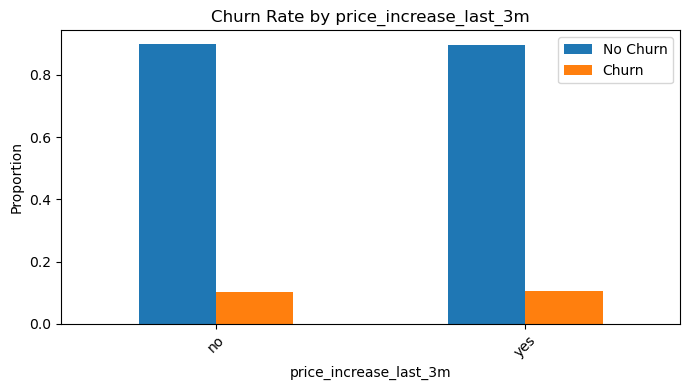

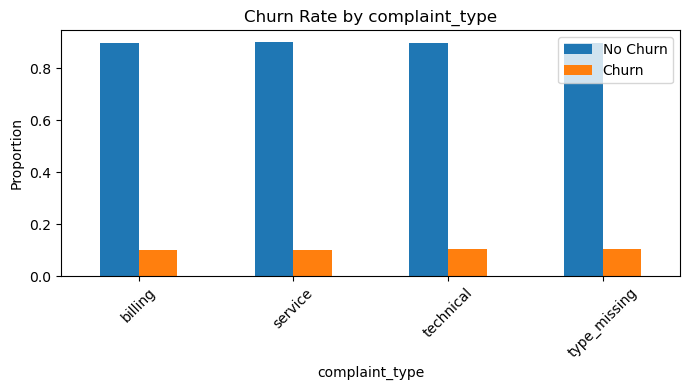

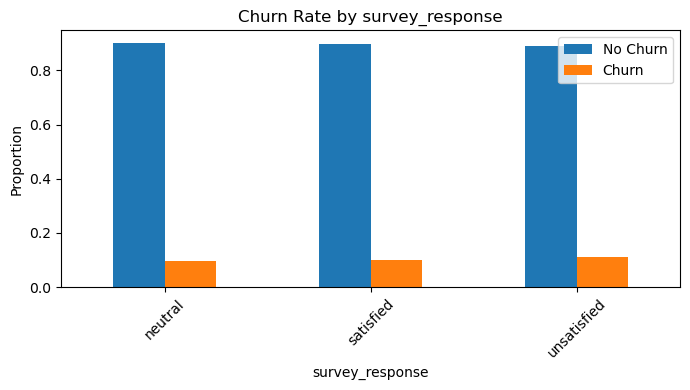

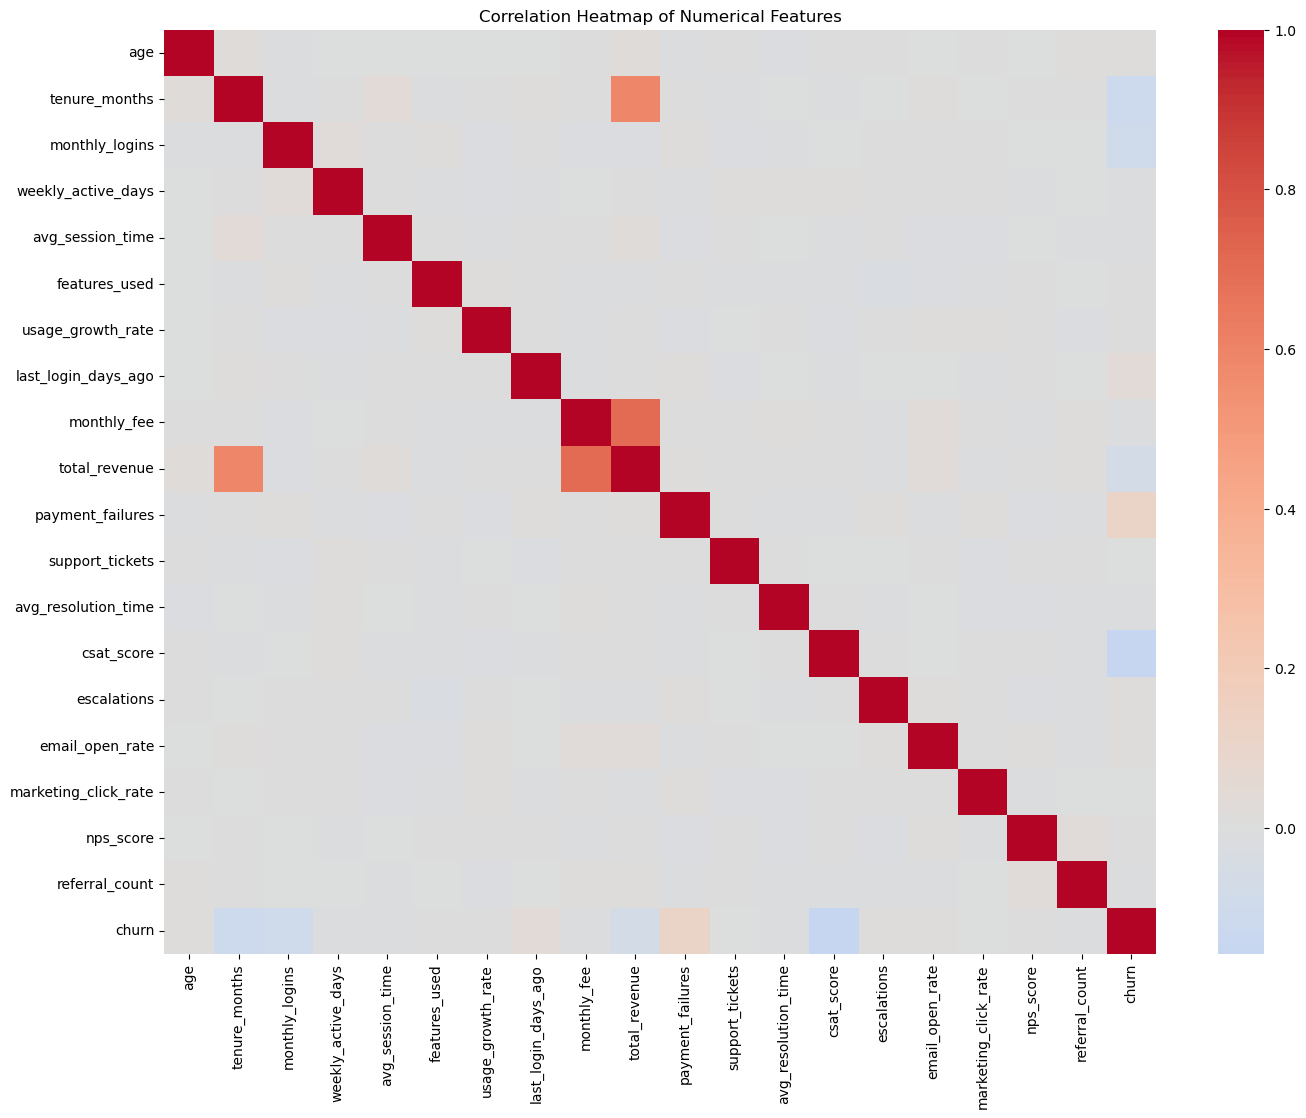

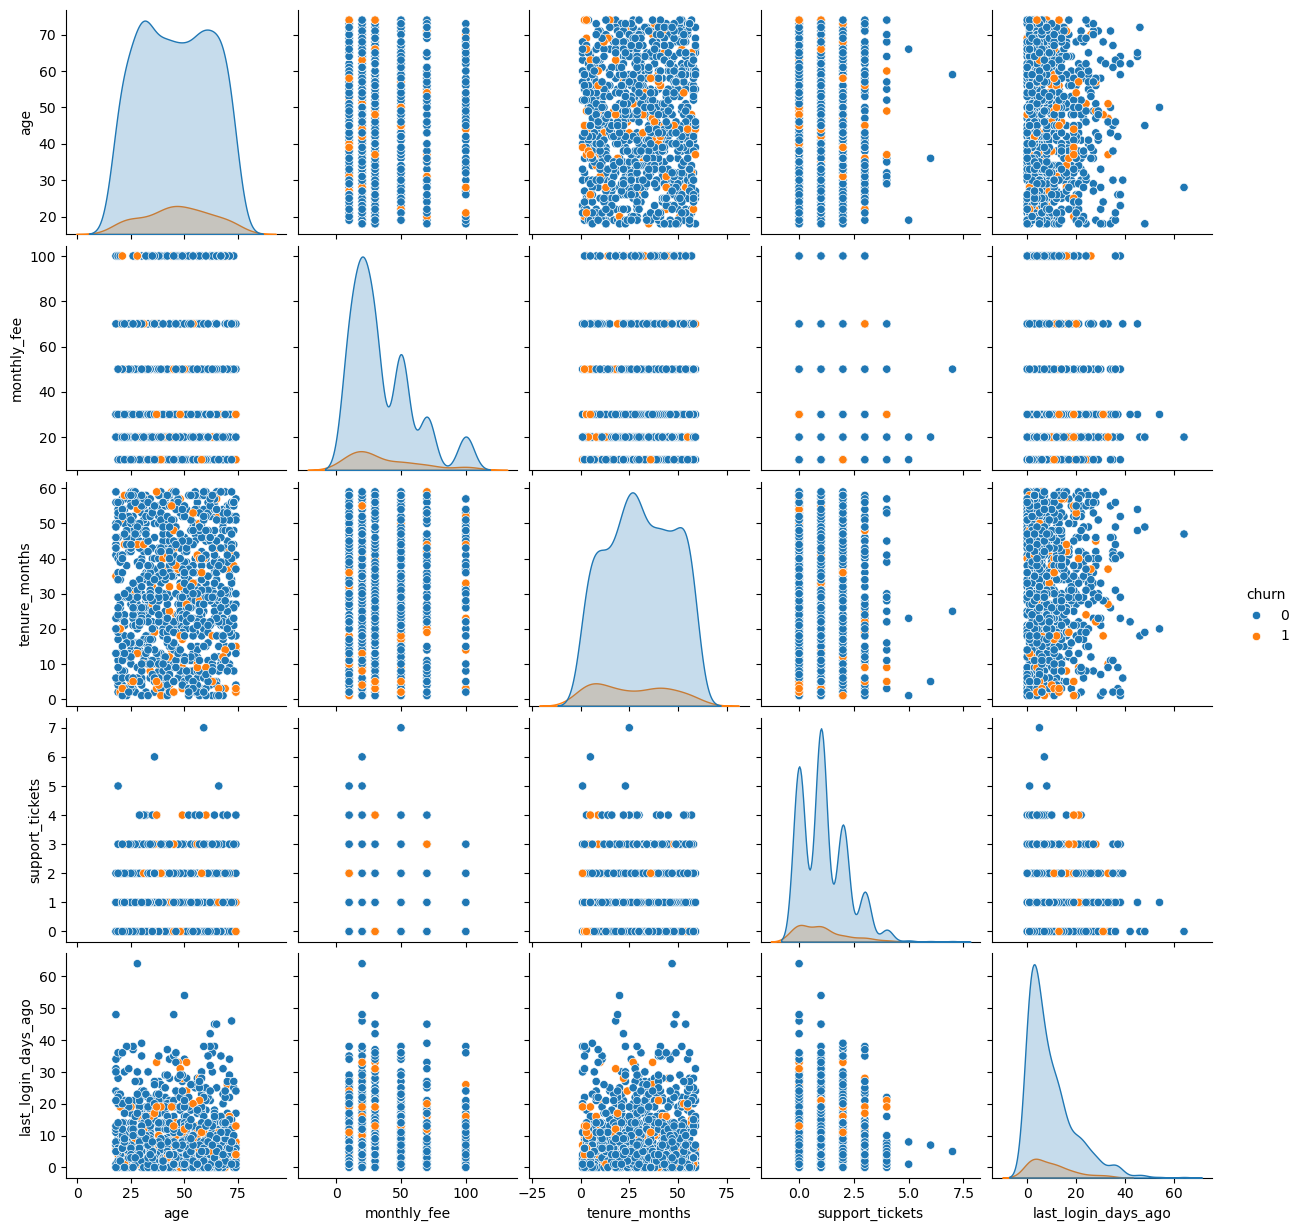

Correlation with Churn
churn                   1.000000
payment_failures        0.112494
last_login_days_ago     0.037250
email_open_rate         0.011506
age                     0.010179
escalations             0.009561
features_used           0.005435
usage_growth_rate       0.005276
nps_score               0.002996
support_tickets         0.000317
marketing_click_rate   -0.002068
avg_session_time       -0.004659
monthly_fee            -0.005048
referral_count         -0.007323
weekly_active_days     -0.008818
avg_resolution_time    -0.009172
total_revenue          -0.070120
monthly_logins         -0.098339
tenure_months          -0.117014
csat_score             -0.157924
Name: churn, dtype: float64
Chi-Square Test Results
----------------------------
gender
p-value: 0.53267
No significant relationship
----------------------------
customer_segment
p-value: 0.36137
No significant relationship
----------------------------
signup_channel
p-value: 0.27731
No significant relationship
----

In [ ]:

# Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu




# Load Cleaned Dataset

CustomerData_Df = pd.read_csv(
    "/Users/manesh/Library/CloudStorage/OneDrive-UniversityofPlymouth/Dissertation /Python_Code/customer_churn_cleaned.csv"
)


print(CustomerData_Df.shape)

CustomerData_Df.info()



# Target Variable Distribution

plt.figure(figsize=(6,4))

sns.countplot(
    x='churn',
    data=CustomerData_Df
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()



print("="*50)
print("Churn Distribution")

print(CustomerData_Df['churn'].value_counts())

print()

print(
    CustomerData_Df['churn']
    .value_counts(normalize=True)
    *100
)



# Numerical Variables vs Churn

numerical_features = [

    'age',
    'monthly_fee',
    'tenure_months',
    'monthly_logins',
    'last_login_days_ago',
    'support_tickets',
    'csat_score',
    'nps_score'

]


for feature in numerical_features:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x='churn',
        y=feature,
        data=CustomerData_Df
    )

    plt.title(f"{feature} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(feature)

    plt.show()

    plt.close()




# Categorical Variables vs Churn
#    (Churn Percentage)



categorical_features = [

    'gender',
    'customer_segment',
    'signup_channel',
    'contract_type',
    'payment_method',
    'discount_applied',
    'price_increase_last_3m',
    'complaint_type',
    'survey_response'

]


for feature in categorical_features:


    churn_rate = pd.crosstab(
        CustomerData_Df[feature],
        CustomerData_Df['churn'],
        normalize='index'
    )


    churn_rate.plot(
        kind='bar',
        figsize=(7,4)
    )


    plt.title(
        f"Churn Rate by {feature}"
    )

    plt.xlabel(feature)

    plt.ylabel(
        "Proportion"
    )

    plt.legend(
        ["No Churn","Churn"]
    )

    plt.xticks(
        rotation=45
    )

    plt.tight_layout()

    plt.show()

    plt.close()



# Correlation Analysis



plt.figure(figsize=(16,12))


correlation_matrix = CustomerData_Df.corr(
    numeric_only=True
)


sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)


plt.title(
    "Correlation Heatmap of Numerical Features"
)


plt.show()




# Pair Plot (Sampled Dataset)


selected_features = [

    'age',
    'monthly_fee',
    'tenure_months',
    'support_tickets',
    'last_login_days_ago',
    'churn'

]


sample_df = CustomerData_Df.sample(
    1000,
    random_state=42
)


sns.pairplot(
    sample_df[selected_features],
    hue='churn'
)


plt.show()




# Correlation Ranking with Churn


churn_correlation = (

    CustomerData_Df
    .corr(numeric_only=True)['churn']
    .sort_values(
        ascending=False
    )

)


print("="*50)

print("Correlation with Churn")

print(churn_correlation)



# Chi-Square Test
#    Categorical Variables


print("="*50)

print("Chi-Square Test Results")


for feature in categorical_features:


    table = pd.crosstab(

        CustomerData_Df[feature],

        CustomerData_Df['churn']

    )


    chi2, p, dof, expected = chi2_contingency(
        table
    )


    print("----------------------------")

    print(feature)

    print(
        "p-value:",
        round(p,5)
    )


    if p < 0.05:

        print(
            "Significant relationship with churn"
        )

    else:

        print(
            "No significant relationship"
        )



# Mann-Whitney U Test
#    Numerical Variables


print("="*50)

print("Mann-Whitney U Test Results")


for feature in numerical_features:


    churned = CustomerData_Df[
        CustomerData_Df['churn']==1
    ][feature]


    not_churned = CustomerData_Df[
        CustomerData_Df['churn']==0
    ][feature]


    statistic, p = mannwhitneyu(

        churned,

        not_churned

    )


    print("----------------------------")

    print(feature)

    print(
        "p-value:",
        round(p,5)
    )


    if p < 0.05:

        print(
            "Significant difference between churn groups"
        )

    else:

        print(
            "No significant difference"
        )



# END OF EDA


print("="*60)

print(
    "EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY"
)

print("="*60)